# Chapter 9 · Stochastic differential equations: interactive demos

Companion to Chapter 9 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/09-sde.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider

from ieor222.sde import (absorbed_fraction, brownian_increments, cev_paths, coarsen, euler_maruyama,
                         gbm_euler_errors, gbm_exact, ou_exact, ou_mean, ou_stationary, ou_var,
                         path_from_increments, picard_iterates)
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
use_style()

## 1. Picard iteration along one Brownian path

The existence proof (Theorem 9.5) builds the solution as the limit of the iterates
$X^{n+1}_t=\xi+\int_0^t b(s,X^n_s)\,ds+\int_0^t\sigma(s,X^n_s)\,dW_s$, started from $X^0\equiv\xi$.
Below, the integrals are left-point sums along one sampled path, for the equation
$dX_t=\sin(X_t)\,dt+(0.2+\sigma\cos X_t)\,dW_t$, whose coefficients are Lipschitz.
The right panel shows the largest distance between consecutive iterates: the proof bounds its
mean square by $M(LT)^n/n!$, which eventually decreases faster than any geometric sequence.

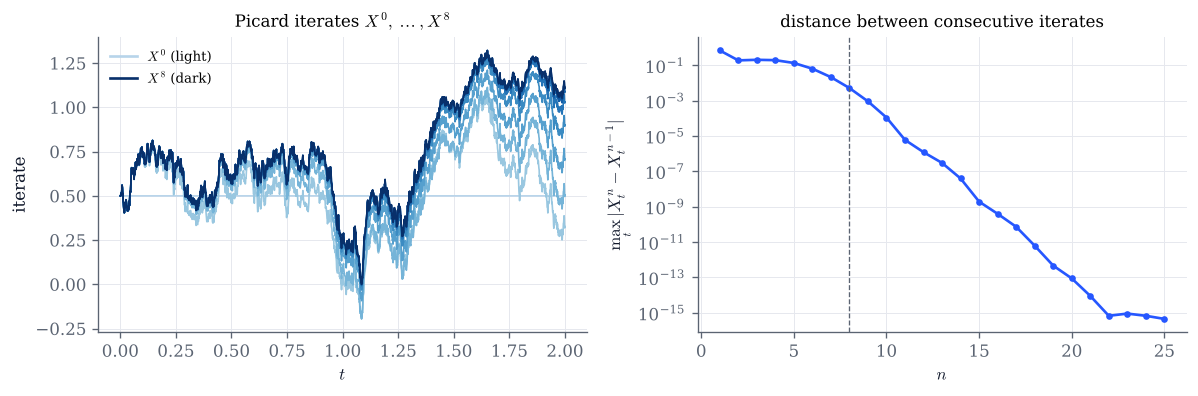

In [2]:
def picard(n_iter=8, sigma=0.5, T=2.0, seed=0):
    n = 2000
    dW = brownian_increments(T, n, n_paths=1, seed=seed)
    t = np.linspace(0, T, n + 1)
    W = path_from_increments(dW)[0]
    b = lambda t, x: np.sin(x)
    s = lambda t, x: 0.2 + sigma * np.cos(x)
    it = picard_iterates(b, s, 0.5, t, W, n_iter=max(n_iter, 25))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    colors = plt.cm.Blues(np.linspace(0.3, 1.0, n_iter + 1))
    for k in range(n_iter + 1):
        ax.plot(t, it[k], color=colors[k], lw=1.0)
    ax.plot([], [], color=colors[0], label="$X^0$ (light)")
    ax.plot([], [], color=colors[-1], label=f"$X^{{{n_iter}}}$ (dark)")
    ax.set(xlabel="$t$", ylabel="iterate", title=f"Picard iterates $X^0,\\dots,X^{{{n_iter}}}$")
    ax.legend(fontsize=8)
    gaps = np.max(np.abs(np.diff(it, axis=0)), axis=1)
    ax2.semilogy(np.arange(1, len(gaps) + 1), np.maximum(gaps, 1e-16), color=COBALT, marker="o", ms=3)
    ax2.axvline(n_iter, color=GREY, lw=0.8, ls="--")
    ax2.set(xlabel="$n$", ylabel="$\\max_t|X^{n}_t-X^{n-1}_t|$", title="distance between consecutive iterates")
    fig.tight_layout()
    plt.show()

picard()

In [3]:
# Explore: more iterations, larger noise, a longer horizon (L T grows, so convergence starts later).
interact(picard,
         n_iter=IntSlider(value=8, min=0, max=25, continuous_update=False, description="iterations"),
         sigma=FloatSlider(value=0.5, min=0.0, max=1.5, step=0.05, continuous_update=False, description="σ"),
         T=FloatSlider(value=2.0, min=0.5, max=8.0, step=0.5, continuous_update=False, description="T"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 2. Euler–Maruyama against the exact solution of geometric Brownian motion

On the left, one Brownian path, the exact solution $S_t=S_0e^{\sigma W_t+(\mu-\sigma^2/2)t}$ along it, and the
Euler–Maruyama scheme with steps $h=T/4$, $T/16$ and $T/256$ driven by the **same** path (the increments of the fine
path are summed). On the right, the strong error $\mathbb E|S_T-S^h_T|$ and the weak error $|\mathbb E S^h_T-\mathbb E S_T|$
estimated on coupled paths, with the exact weak error $S_0|e^{\mu T}-(1+\mu h)^{T/h}|$ of Example 9.17.
Theorem 9.16: slopes $1/2$ and $1$ on log–log axes.

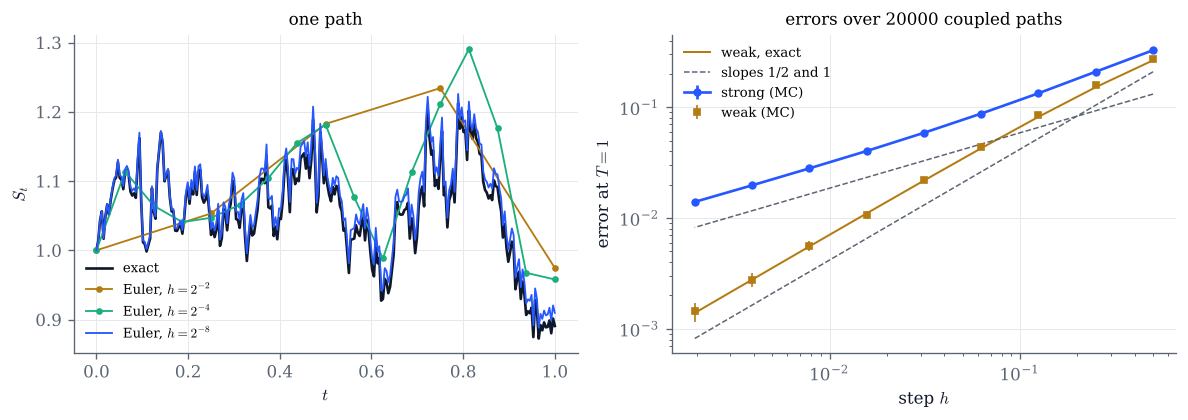

In [4]:
def euler(mu=0.8, sigma=0.5, n_paths=20_000, seed=1):
    S0, T, K = 1.0, 1.0, 8
    dW = brownian_increments(T, 2**K, n_paths=1, seed=seed)
    t = np.linspace(0, T, 2**K + 1)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
    ax.plot(t, gbm_exact(S0, mu, sigma, t, path_from_increments(dW))[0], color=INK, lw=1.6, label="exact")
    for k, c in ((2, GOLD), (4, GREEN), (8, COBALT)):
        tk, Sk = euler_maruyama(lambda t, x: mu * x, lambda t, x: sigma * x, S0, T, 2**k,
                                dW=coarsen(dW, 2 ** (K - k)))
        ax.plot(tk, Sk[0], color=c, lw=1.1, marker="o" if k < 8 else None, ms=3, label=f"Euler, $h=2^{{-{k}}}$")
    ax.set(xlabel="$t$", ylabel="$S_t$", title="one path")
    ax.legend(fontsize=8)
    r = gbm_euler_errors(S0, mu, sigma, T, levels=range(1, 10), n_paths=n_paths, seed=seed + 1)
    h = r["h"]
    ax2.errorbar(h, r["strong"], yerr=1.96 * r["strong_se"], color=COBALT, marker="o", ms=4, label="strong (MC)")
    ax2.errorbar(h, np.abs(r["weak"]), yerr=1.96 * r["weak_se"], color=GOLD, marker="s", ms=4, lw=0,
                 elinewidth=1, label="weak (MC)")
    if mu != 0:
        ax2.plot(h, np.abs(r["weak_exact"]), color=GOLD, lw=1.2, label="weak, exact")
    ax2.plot(h, r["strong"][-1] * (h / h[-1]) ** 0.5 / 1.7, color=GREY, ls="--", lw=0.9, label="slopes 1/2 and 1")
    ax2.plot(h, max(abs(r["weak_exact"][-1]), 1e-6) * (h / h[-1]) / 1.7, color=GREY, ls="--", lw=0.9)
    ax2.set(xscale="log", yscale="log", xlabel="step $h$", ylabel="error at $T=1$",
            title=f"errors over {n_paths} coupled paths")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

euler()

In [5]:
# Explore: what happens to the weak error for f(x) = x when mu = 0? And to the strong error when sigma grows?
interact(euler,
         mu=FloatSlider(value=0.8, min=-1.0, max=2.0, step=0.1, continuous_update=False, description="μ"),
         sigma=FloatSlider(value=0.5, min=0.05, max=1.5, step=0.05, continuous_update=False, description="σ"),
         n_paths=IntSlider(value=20_000, min=2_000, max=100_000, step=2_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 3. Ornstein–Uhlenbeck paths and the stationary law

Paths of $dX_t=\kappa(\theta-X_t)\,dt+\sigma\,dW_t$ simulated **exactly** on the grid with the Gaussian transition of
Proposition 9.8(i): given $X_t$, $X_{t+h}$ is normal with mean $\theta+(X_t-\theta)e^{-\kappa h}$ and variance
$\sigma^2(1-e^{-2\kappa h})/(2\kappa)$. On the right, the histogram of $X_t$ at the time $t$ you choose, the exact law
$\mathcal N\big(\theta+(x_0-\theta)e^{-\kappa t},\ \sigma^2(1-e^{-2\kappa t})/(2\kappa)\big)$, and the stationary law
$\mathcal N(\theta,\sigma^2/(2\kappa))$.

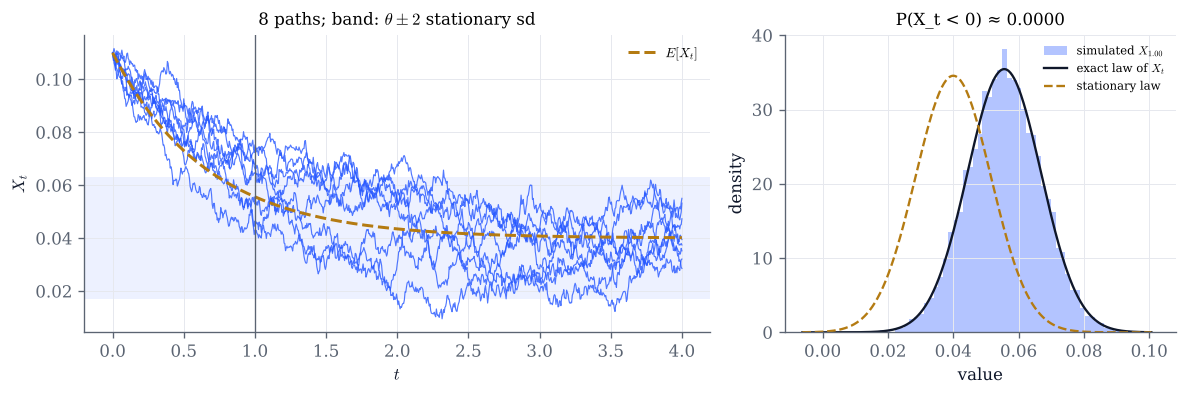

In [6]:
def ou(kappa=1.5, theta=0.04, sigma=0.02, x0=0.11, t_show=1.0, seed=2):
    T = 4.0
    t, X = ou_exact(x0, kappa, theta, sigma, T, 800, n_paths=20_000, seed=seed)
    m, v = ou_stationary(kappa, theta, sigma)
    k = int(round(t_show / T * 800))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
    ax.axhspan(m - 2 * np.sqrt(v), m + 2 * np.sqrt(v), color=COBALT, alpha=0.08, lw=0)
    ax.plot(t, X[:8].T, color=COBALT, lw=0.7, alpha=0.8)
    ax.plot(t, ou_mean(x0, kappa, theta, t), color=GOLD, lw=1.8, ls="--", label="$E[X_t]$")
    ax.axvline(t[k], color=GREY, lw=0.8)
    ax.set(xlabel="$t$", ylabel="$X_t$", title="8 paths; band: $\\theta\\pm2$ stationary sd")
    ax.legend(fontsize=8)
    ax2.hist(X[:, k], bins=60, density=True, color=COBALT, alpha=0.35, label=f"simulated $X_{{{t[k]:.2f}}}$")
    sd_t, sd = np.sqrt(ou_var(kappa, sigma, t[k])), np.sqrt(v)
    mt = ou_mean(x0, kappa, theta, t[k])
    x = np.linspace(min(mt - 4 * sd_t, m - 4 * sd), max(mt + 4 * sd_t, m + 4 * sd), 400)
    if sd_t > 0:
        ax2.plot(x, np.exp(-0.5 * ((x - mt) / sd_t) ** 2) / (sd_t * np.sqrt(2 * np.pi)), color=INK, lw=1.4,
                 label="exact law of $X_t$")
    ax2.plot(x, np.exp(-0.5 * ((x - m) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)), color=GOLD, lw=1.4, ls="--",
             label="stationary law")
    ax2.set(xlabel="value", ylabel="density", title=f"P(X_t < 0) ≈ {np.mean(X[:, k] < 0):.4f}")
    ax2.legend(fontsize=7)
    fig.tight_layout()
    plt.show()

ou()

In [7]:
# Explore: the mean forgets x0 at rate kappa, the variance levels off at sigma^2 / (2 kappa).
interact(ou,
         kappa=FloatSlider(value=1.5, min=0.1, max=5.0, step=0.1, continuous_update=False, description="κ"),
         theta=FloatSlider(value=0.04, min=-0.02, max=0.10, step=0.005, continuous_update=False, description="θ"),
         sigma=FloatSlider(value=0.02, min=0.002, max=0.08, step=0.002, continuous_update=False, description="σ"),
         x0=FloatSlider(value=0.11, min=-0.05, max=0.20, step=0.005, continuous_update=False, description="x0"),
         t_show=FloatSlider(value=1.0, min=0.0, max=4.0, step=0.05, continuous_update=False, description="t"),
         seed=IntSlider(value=2, min=0, max=100, continuous_update=False, description="seed"));

## 4. CEV paths near zero

The CEV model $dS_t=\mu S_t\,dt+\sigma S_t^\gamma\,dW_t$ (Example 9.15), simulated by the Euler scheme with absorption
at $0$. For $\gamma<1$ the volatility of returns $\sigma S^{\gamma-1}$ explodes as the price falls, the Lipschitz
theorem does not apply at $0$, and paths can reach $0$. On the right, the fraction of paths absorbed by time $t$
for your $\gamma$, next to geometric Brownian motion ($\gamma=1$), which never reaches $0$.

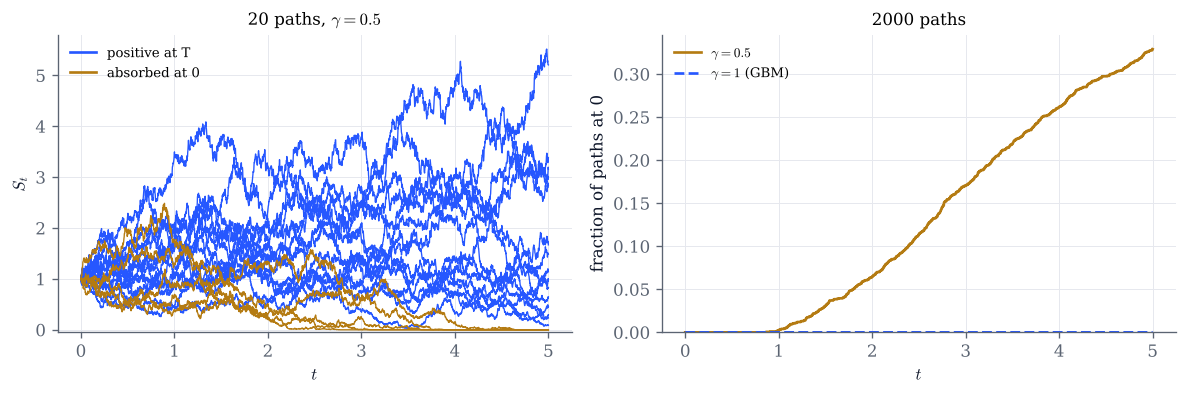

In [8]:
def cev(gamma=0.5, sigma=0.6, mu=0.0, T=5.0, seed=3):
    S0, n = 1.0, 2_500
    t, S = cev_paths(S0, mu, sigma, gamma, T, n, n_paths=2_000, seed=seed)
    _, S1 = cev_paths(S0, mu, sigma, 1.0, T, n, n_paths=2_000, seed=seed)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    dead = S[:20, -1] <= 0
    for row, d in zip(S[:20], dead):
        ax.plot(t, row, color=GOLD if d else COBALT, lw=0.8, zorder=3 if d else 2)
    ax.plot([], [], color=COBALT, label="positive at T")
    ax.plot([], [], color=GOLD, label="absorbed at 0")
    ax.set(xlabel="$t$", ylabel="$S_t$", title=f"20 paths, $\\gamma={gamma:g}$", ylim=(-0.05, None))
    ax.legend(fontsize=8)
    ax2.plot(t, absorbed_fraction(S), color=GOLD, lw=1.6, label=f"$\\gamma={gamma:g}$")
    ax2.plot(t, absorbed_fraction(S1), color=COBALT, lw=1.6, ls="--", label="$\\gamma=1$ (GBM)")
    ax2.set(xlabel="$t$", ylabel="fraction of paths at 0", title="2000 paths", ylim=(0, None))
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

cev()

In [9]:
# Explore: the elasticity gamma, the volatility level sigma (the volatility of returns at S = 1), and a drift mu.
interact(cev,
         gamma=FloatSlider(value=0.5, min=0.1, max=1.5, step=0.05, continuous_update=False, description="γ"),
         sigma=FloatSlider(value=0.6, min=0.1, max=1.2, step=0.05, continuous_update=False, description="σ"),
         mu=FloatSlider(value=0.0, min=-0.2, max=0.3, step=0.05, continuous_update=False, description="μ"),
         T=FloatSlider(value=5.0, min=1.0, max=10.0, step=0.5, continuous_update=False, description="T"),
         seed=IntSlider(value=3, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $\sigma=0$: the equation becomes an ordinary differential equation. Does Picard iteration converge
  faster or slower? Then increase $T$: why does the distance between iterates first grow before it collapses?
- In section 2, set $\mu=0$. The weak error for $f(x)=x$ disappears (Example 9.17), but the strong error does not.
  Why is that not a contradiction?
- In section 3, take $\kappa$ small and $x_0$ far from $\theta$. How long until the law of $X_t$ is close to the
  stationary law? Compare with the half-life $\log 2/\kappa$.
- In section 4, take $\gamma$ slightly above $1$. Do paths still reach $0$? What happens to the paths that go up?